# Chapter 24: The Average Is Hiding Something

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** look at the data *behind* an average. You will see why repeated values must stay in the list, how two different datasets can share the same mean, why the median needs a sorted list, and how one high value can drag the mean far away from the median.

The code cells are optional reading. Every result and picture is shown right below the code, so you can follow along without running anything.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction as F

INK, TERRACOTTA, NAVY, TEAL, GREY, LIGHT, GOLD = "#222222", "#c0563b", "#1f3a5f", "#2a8a85", "#777777", "#dddddd", "#b8860b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def show(x):
    """A mean or median the way the book writes it: whole, decimal, or fraction with a rounded decimal."""
    x = F(x)
    if x.denominator == 1:
        return str(x.numerator)
    d = x.denominator
    while d % 2 == 0: d //= 2
    while d % 5 == 0: d //= 5
    return f"{float(x):g}" if d == 1 else f"{x.numerator}/{x.denominator}, about {float(x):.2f}"

def median(values):
    s = sorted(values); k = len(s)
    return F(s[k // 2]) if k % 2 else F(s[k // 2 - 1] + s[k // 2], 2)

def plus(values):
    return " + ".join(str(v) for v in values)
print("Setup done.")

Setup done.


## Demonstration 1: Every repeat is a person

**The question, in plain words:** Three waiting times are 3, 3 and 8. What happens to the mean if a repeat is dropped?

**The equations:**

$$(3+3+8)/3 = 14/3 \qquad\qquad (3+8)/2 = 5.5$$

**What the symbols mean:**
- Square brackets hold a data list, where repeats count: $[3, 3, 8]$.
- The *mean* is the sum of the listed values divided by how many there are.

**Predict first:** before choosing one copy of 3, guess whether the mean goes up or down.

In [2]:
copies = 2
data = [3] * copies + [8]
total, k = sum(data), len(data)
mean = F(total, k)
print(f"List: {data}  ({k} observations)")
print(f"Sum: {plus(data)} = {total}")
print(f"Mean = {total}/{k} = {show(mean)}")
print(f"Dropping one 3 would give (3 + 8)/2 = {show(F(11, 2))}")
print()
print("Other menu values:")
for cp in (1, 2, 3, 4):
    d = [3] * cp + [8]
    print(f"{cp} cop{'y' if cp == 1 else 'ies'} of 3: ({plus(d)})/{len(d)} = {sum(d)}/{len(d)} = {show(F(sum(d), len(d)))}")

List: [3, 3, 8]  (3 observations)
Sum: 3 + 3 + 8 = 14
Mean = 14/3 = 14/3, about 4.67
Dropping one 3 would give (3 + 8)/2 = 5.5

Other menu values:
1 copy of 3: (3 + 8)/2 = 11/2 = 5.5
2 copies of 3: (3 + 3 + 8)/3 = 14/3 = 14/3, about 4.67
3 copies of 3: (3 + 3 + 3 + 8)/4 = 17/4 = 4.25
4 copies of 3: (3 + 3 + 3 + 3 + 8)/5 = 20/5 = 4


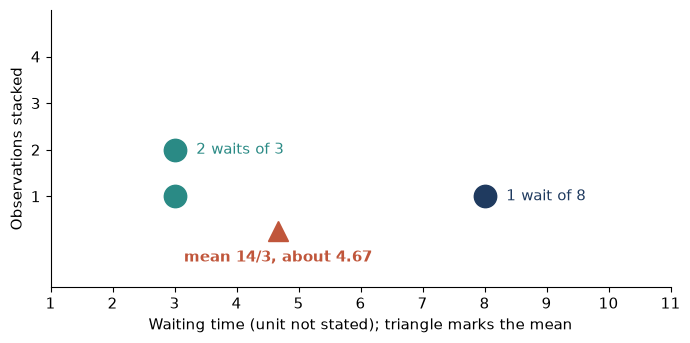

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter([3] * copies, range(1, copies + 1), s=260, color=TEAL, zorder=3)
ax.scatter([8], [1], s=260, color=NAVY, zorder=3)
ax.text(3.35, copies, f"{copies} waits of 3", va="center", color=TEAL)
ax.text(8.35, 1, "1 wait of 8", va="center", color=NAVY)
ax.plot([float(mean)], [0.25], marker="^", markersize=14, color=TERRACOTTA, zorder=3)
ax.text(float(mean), -0.15, f"mean {show(mean)}", ha="center", va="top", color=TERRACOTTA, fontweight="bold")
ax.set_xlim(1, 11); ax.set_ylim(-0.95, 5.0); ax.set_yticks(range(1, 5)); ax.set_xticks(range(1, 12))
ax.set_xlabel("Waiting time (unit not stated); triangle marks the mean")
ax.set_ylabel("Observations stacked")
plt.show()

**What this shows:** each dot is one observation. Adding a copy of 3 adds 3 to the sum and 1 to the count, so the balance point slides toward 3. Two equal waits are still two people waiting, so the book's list $[3, 3, 8]$ has mean $14/3$, about $4.67$, not $5.5$.

**Where it stops working:** this treats every observation as one entry. Treating the list as a *set* would silently drop repeats and answer a different question. The values here have no unit stated, so do not read them as minutes unless the data say so.

## Demonstration 2: Same mean, different data

**The question, in plain words:** Datasets A and B both have mean 6. Are they the same data?

**The equations:**

$$\text{mean} = \frac{\text{sum of values}}{\text{number of values}} \qquad\qquad \text{mean}(B) = (0 + 0 + 6 + 12 + 12)/5$$

**What the symbols mean:**
- $A = [2, 4, 6, 8, 10]$ and $B = [0, 0, 6, 12, 12]$.
- Each mark in the picture is one value, placed on the value scale. The "leveled" view shares the total out equally, so all five marks stack at 6.

**Predict first:** before looking at B, guess how many of its values sit exactly 6 units from the mean.

In [4]:
A, B = [2, 4, 6, 8, 10], [0, 0, 6, 12, 12]
for name, d in (("A", A), ("B", B)):
    tot = sum(d)
    far = sum(1 for v in d if abs(v - 6) == 6)
    print(f"Dataset {name} = {d}")
    print(f"  sum: {plus(d)} = {tot}")
    print(f"  mean = {tot}/{len(d)} = {show(F(tot, len(d)))}")
    print(f"  values exactly 6 units from the mean: {far}")

Dataset A = [2, 4, 6, 8, 10]
  sum: 2 + 4 + 6 + 8 + 10 = 30
  mean = 30/5 = 6
  values exactly 6 units from the mean: 0
Dataset B = [0, 0, 6, 12, 12]
  sum: 0 + 0 + 6 + 12 + 12 = 30
  mean = 30/5 = 6
  values exactly 6 units from the mean: 4


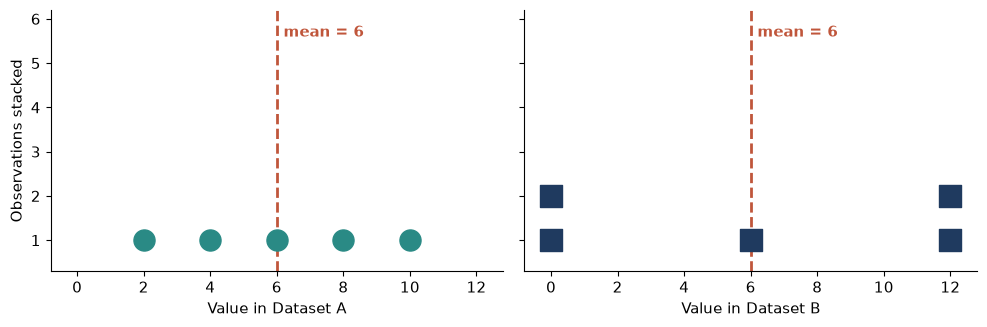

Leveled view: total 30 shared across 5 values = 30/5 = 6 each, so five marks stack at 6.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (name, d, col, mk) in zip(axes, (("A", A, TEAL, "o"), ("B", B, NAVY, "s"))):
    counts = {}
    for v in d:
        counts[v] = counts.get(v, 0) + 1
        ax.scatter([v], [counts[v]], s=230, marker=mk, color=col, zorder=3)
    ax.axvline(6, color=TERRACOTTA, linestyle="dashed", linewidth=2)
    ax.text(6.2, 5.6, "mean = 6", color=TERRACOTTA, fontweight="bold")
    ax.set_xlim(-0.8, 12.8); ax.set_ylim(0.3, 6.2); ax.set_xticks(range(0, 13, 2))
    ax.set_xlabel(f"Value in Dataset {name}")
axes[0].set_ylabel("Observations stacked")
plt.tight_layout(); plt.show()

# The leveled view: share the total of 30 out equally
print("Leveled view: total 30 shared across 5 values = 30/5 =", 30 // 5, "each, so five marks stack at 6.")

**What this shows:** both datasets total 30 across 5 values, so sharing out gives 6 everywhere. The mean *is* that leveled picture. The raw dot plot keeps what the mean leaves out: A steps away from 6 evenly in both directions, while B has four of its five values 6 units away.

**Where it stops working:** these are two small constructed lists. The mean is exact; calling 6 a "typical" value is a judgment the numbers alone do not make. When a report gives only an average, ask for the count, the unit and the raw values.

## Demonstration 3: Sort first, then find the middle

**The question, in plain words:** Waiting times were recorded as 9, 2, 7, 3, 4. What is the median?

**The equations:**

$$(9+2+7+3+4)/5 = 25/5 = 5 \qquad\qquad (4+6)/2 = 5$$

**What the symbols mean:**
- The *median* is the middle value **after sorting**. With an even count it is the mean of the two middle values.
- The *range* is the largest value minus the smallest.
- The five waiting times are in minutes; the four-value list $[8, 2, 6, 4]$ has no stated unit.

**Predict first:** if you just take the middle of the list as recorded, will you get the median?

In [6]:
for name, rec in (("odd", [9, 2, 7, 3, 4]), ("even", [8, 2, 6, 4])):
    srt = sorted(rec)
    k = len(rec)
    mid_unsorted = F(rec[k // 2]) if k % 2 else F(rec[k // 2 - 1] + rec[k // 2], 2)
    print(f"Recorded: {rec}")
    print(f"  middle of the unsorted record: {show(mid_unsorted)}  (not the median)")
    print(f"  sorted:   {srt}")
    if k % 2:
        print(f"  median = the third value = {srt[k // 2]}")
    else:
        print(f"  central pair {srt[1]}, {srt[2]}: median = ({srt[1]} + {srt[2]})/2 = {show(median(rec))}")
    print(f"  mean   = ({plus(rec)})/{k} = {sum(rec)}/{k} = {show(F(sum(rec), k))}")
    print(f"  range  = {srt[-1]} - {srt[0]} = {srt[-1] - srt[0]}")
    print()

Recorded: [9, 2, 7, 3, 4]
  middle of the unsorted record: 7  (not the median)
  sorted:   [2, 3, 4, 7, 9]
  median = the third value = 4
  mean   = (9 + 2 + 7 + 3 + 4)/5 = 25/5 = 5
  range  = 9 - 2 = 7

Recorded: [8, 2, 6, 4]
  middle of the unsorted record: 4  (not the median)
  sorted:   [2, 4, 6, 8]
  central pair 4, 6: median = (4 + 6)/2 = 5
  mean   = (8 + 2 + 6 + 4)/4 = 20/4 = 5
  range  = 8 - 2 = 6



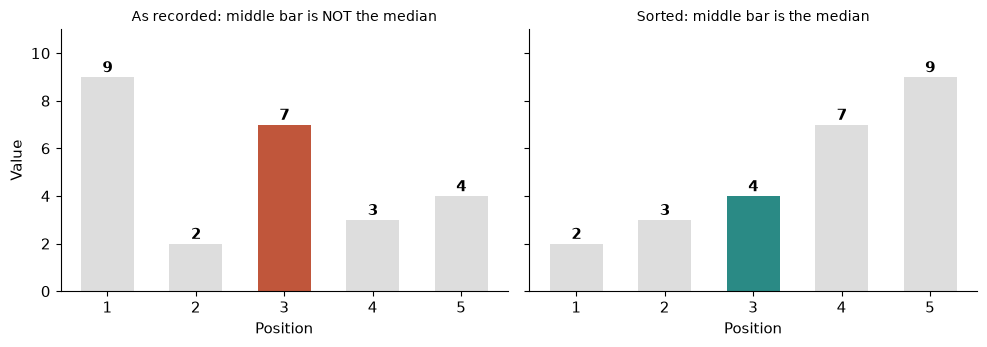

In [7]:
rec = [9, 2, 7, 3, 4]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (title, shown, good) in zip(axes, (("As recorded", rec, False), ("Sorted", sorted(rec), True))):
    mid = len(shown) // 2
    colors = [(TEAL if good else TERRACOTTA) if i == mid else LIGHT for i in range(len(shown))]
    ax.bar(range(len(shown)), shown, width=0.6, color=colors)
    for i, v in enumerate(shown):
        ax.text(i, v + 0.2, str(v), ha="center", fontweight="bold")
    ax.set_xticks(range(len(shown))); ax.set_xticklabels([str(i + 1) for i in range(len(shown))])
    ax.set_xlabel("Position"); ax.set_title(title + (": middle bar is the median" if good else ": middle bar is NOT the median"), fontsize=10)
    ax.set_ylim(0, 11)
axes[0].set_ylabel("Value")
plt.tight_layout(); plt.show()

**What this shows:** sorting moves the bars into order, and then the middle bar (highlighted) really is in the middle of the data. Unsorted, the middle bar of the record is just whatever happened to be recorded there: 7 for the first list, when the true median is 4. For the four-value list the unsorted middle pair gives $(2 + 6)/2 = 4$, but the sorted pair gives $(4 + 6)/2 = 5$. Sorting keeps the sum and the count, so the mean does not change.

**Where it stops working:** these are small constructed lists. With an even count the median may equal none of the observations, and that is fine. The median ignores how far the other values are from the middle, which is why the next demonstration matters.

## Demonstration 4: One high value pulls the mean

**The question, in plain words:** In $[1, 1, 1, 1, 21]$, why are the mean and the median so far apart?

**The equations:**

$$(1 + 1 + 1 + 1 + 21)/5 = 25/5 = 5 \qquad\qquad 21 - 1 = 20$$

**What the symbols mean:**
- The mean uses every value through the total.
- The median is the third value in order.
- The range is largest minus smallest.

**Predict first:** change the fifth value from 21 to 101. What happens to the mean? To the median?

In [8]:
for high in (1, 6, 21, 101):
    d = [1, 1, 1, 1, high]
    tot = sum(d)
    srt = sorted(d)
    print(f"[1, 1, 1, 1, {high}]: mean = ({plus(d)})/5 = {tot}/5 = {show(F(tot, 5))}, "
          f"median = {srt[2]}, range = {srt[-1]} - {srt[0]} = {srt[-1] - srt[0]}")

[1, 1, 1, 1, 1]: mean = (1 + 1 + 1 + 1 + 1)/5 = 5/5 = 1, median = 1, range = 1 - 1 = 0
[1, 1, 1, 1, 6]: mean = (1 + 1 + 1 + 1 + 6)/5 = 10/5 = 2, median = 1, range = 6 - 1 = 5
[1, 1, 1, 1, 21]: mean = (1 + 1 + 1 + 1 + 21)/5 = 25/5 = 5, median = 1, range = 21 - 1 = 20
[1, 1, 1, 1, 101]: mean = (1 + 1 + 1 + 1 + 101)/5 = 105/5 = 21, median = 1, range = 101 - 1 = 100


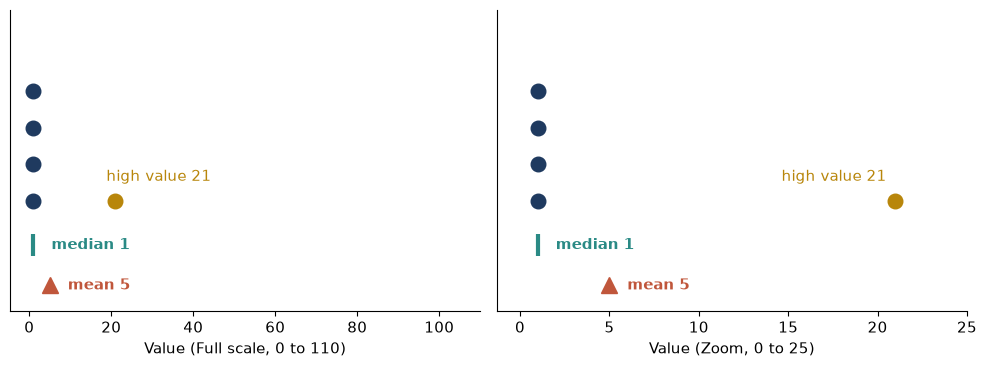

In [9]:
high = 21
d = [1, 1, 1, 1, high]
mean_v, med_v = F(sum(d), 5), median(d)
fig, (full, zoom) = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, xmax, title in ((full, 110, "Full scale, 0 to 110"), (zoom, 25, "Zoom, 0 to 25")):
    ax.scatter([1] * 4, range(1, 5), s=110, color=NAVY, zorder=3)
    ax.scatter([high], [1], s=110, color=GOLD, zorder=3)
    ax.text(high - xmax * 0.02, 1.55, f"high value {high}", ha="right" if high > 0.6 * xmax else "left", color=GOLD)
    ax.plot([float(med_v)], [-0.2], marker="|", markersize=16, markeredgewidth=3, color=TEAL)
    ax.text(float(med_v) + xmax * 0.04, -0.2, f"median {show(med_v)}", va="center", color=TEAL, fontweight="bold")
    ax.plot([float(mean_v)], [-1.3], marker="^", markersize=12, color=TERRACOTTA)
    ax.text(float(mean_v) + xmax * 0.04, -1.3, f"mean {show(mean_v)}", va="center", color=TERRACOTTA, fontweight="bold")
    ax.set_xlim(-0.04 * xmax - 0.3, xmax); ax.set_ylim(-2.0, 6.2); ax.set_yticks([])
    ax.set_xlabel(f"Value ({title})")
plt.tight_layout(); plt.show()

**What this shows:** one high value pulls the mean from 1 up to 5, while the median stays at 1 because four of the five ordered positions hold 1. The range, $21 - 1 = 20$, warns you that the list is spread out even though the median looks calm. At 101 the mean becomes 21 and the zoomed picture cannot even show the dot.

**Where it stops working:** this is a constructed list. The chapter calls 21 a single high value, not an outlier: whether a value is "wrong" or just rare is a question about where the data came from, and the arithmetic cannot settle it. Report the center together with the spread and the raw values.

## Practice

**1.** What is the mean of $[5, 5, 5, 9]$?

<details><summary>Show answer</summary>

Sum: $5 + 5 + 5 + 9 = 24$. Count: 4.
Mean: $24/4 = 6$.

</details>

**2.** What is the median of $[10, 1, 7, 4, 3, 12]$?

<details><summary>Show answer</summary>

Sort first: $[1, 3, 4, 7, 10, 12]$.
Six values, so the central pair is 4 and 7.
Median: $(4 + 7)/2 = 5.5$.

</details>

**3.** For $[1, 1, 1, 1, 101]$, what are the mean, median and range?

<details><summary>Show answer</summary>

Mean: $(1 + 1 + 1 + 1 + 101)/5 = 105/5 = 21$.
Median: sorted list is the same, third value is $1$.
Range: $101 - 1 = 100$.

</details>